# Predviđanje odlaska klijenata (churn): stablo odlučivanja

**Cilj:** predvideti da li će klijent banke otići, kako bi banka ponudu za zadržavanje usmerila na prave ljude.

**Podaci:** oko 4.900 klijenata banke sa demografskim podacima, aktivnošću na računu i oznakom odlaska (`Exited`).

**Postupak:** čišćenje podataka, istraživačka analiza i izbor atributa, kodiranje kategorijskih varijabli, stablo odlučivanja sa podrezivanjem podešeno stratifikovanom 10-strukom kros validacijom i evaluacija sa fokusom na klijente koji odlaze.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             recall_score, precision_score, f1_score, roc_auc_score)

## 1. Učitavanje i pregled podataka

In [2]:
df = pd.read_csv('data/bank.csv', na_values=['', ' ', '-', 'NA'])
print(df.shape)
df.head()

(4898, 15)
    Surname  CreditScore Geography  Gender   Age  Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited  Satisfaction.Score Card.Type  Point.Earned
0  Hargrave          619    France  Female   NaN       2       0.00              1          1               1        101348.88       1                   2   DIAMOND           464
1      Hill          608     Spain  Female  41.0       1   83807.86              1          0               1        112542.58       0                   3   DIAMOND           456
2      Onio          502    France  Female  42.0       8  159660.80              3          1               0        113931.57       1                   3   DIAMOND           377
3      Boni          699    France  Female  39.0       1       0.00              2          0               0         93826.63       0                   5      GOLD           350
4       NaN          850     Spain  Female  43.0       2  125510.82              1          1 

In [3]:
df.isna().sum()

Surname               1
CreditScore           0
Geography             2
Gender                0
Age                   3
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Satisfaction.Score    0
Card.Type             0
Point.Earned          0


## 2. Čišćenje podataka
- `Age` ima nedostajuće vrednosti koje menjamo **medijanom**, jer je raspodela asimetrična pa je medijana otpornija od proseka.
- Izbacujemo nerealne godine (preko 87).
- `Surname` nema veze sa odlaskom klijenta, pa izbacujemo kolonu.
- Dva reda bez vrednosti za `Geography` izbacujemo, jer su zanemarljiv deo podataka.

In [4]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df = df[df['Age'] <= 87]
df = df.drop(columns='Surname').dropna(subset=['Geography'])
print(df.shape)
print('Preostalih nedostajućih vrednosti:', df.isna().sum().sum())

(4895, 14)
Preostalih nedostajućih vrednosti: 0


## 3. Ciljna varijabla
`Exited = 1` znači da je klijent otišao. Klase su **neuravnotežene**: otprilike svaki peti klijent odlazi, pa sama tačnost (accuracy) može da zavara.

In [5]:
df['Exited'].value_counts(normalize=True).round(3)

Exited
0    0.791
1    0.209


## 4. Istraživačka analiza i izbor atributa
Za svaki atribut poredimo raspodelu kod klijenata koji odlaze i onih koji ostaju. Vizuelnu procenu proveravamo statističkim testom:
**Mann-Whitney U** za numeričke i **hi-kvadrat test** za kategorijske atribute (p < 0,05 znači da se atribut razlikuje između grupa).

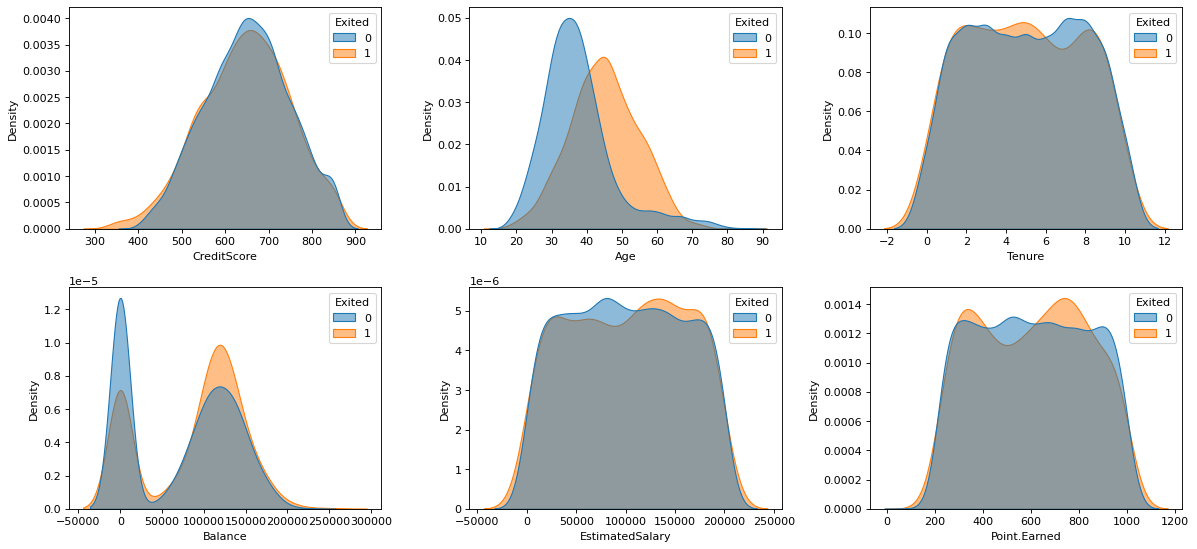

In [6]:
numeric = ['CreditScore', 'Age', 'Tenure', 'Balance', 'EstimatedSalary', 'Point.Earned']
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), numeric):
    sb.kdeplot(data=df, x=col, hue='Exited', fill=True, common_norm=False, alpha=0.5, ax=ax)
plt.tight_layout()
plt.show()

In [7]:
categorical = ['Geography', 'Gender', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Satisfaction.Score', 'Card.Type']
rows = []
for col in numeric:
    p = mannwhitneyu(df.loc[df.Exited == 1, col], df.loc[df.Exited == 0, col]).pvalue
    rows.append((col, 'Mann-Whitney U', p))
for col in categorical:
    p = chi2_contingency(pd.crosstab(df[col], df['Exited']))[1]
    rows.append((col, 'Hi-kvadrat', p))
tests = pd.DataFrame(rows, columns=['atribut', 'test', 'p_vrednost']).sort_values('p_vrednost')
tests['znacajan'] = tests['p_vrednost'] < 0.05
tests

               atribut            test     p_vrednost  znacajan
8        NumOfProducts      Hi-kvadrat  5.775482e-165      True
1                  Age  Mann-Whitney U  3.950594e-118      True
10      IsActiveMember      Hi-kvadrat   2.235756e-33      True
6            Geography      Hi-kvadrat   4.526620e-26      True
7               Gender      Hi-kvadrat   6.853769e-15      True
3              Balance  Mann-Whitney U   1.968209e-10      True
0          CreditScore  Mann-Whitney U   3.132434e-01     False
2               Tenure  Mann-Whitney U   4.003403e-01     False
12           Card.Type      Hi-kvadrat   4.175199e-01     False
11  Satisfaction.Score      Hi-kvadrat   4.904474e-01     False
4      EstimatedSalary  Mann-Whitney U   6.528697e-01     False
9            HasCrCard      Hi-kvadrat   7.901703e-01     False
5         Point.Earned  Mann-Whitney U   9.505858e-01     False


Statistički testovi potvrđuju vizuelnu analizu. **Odluka:** zadržavamo atribute koji jasno razdvajaju dve grupe: `Age`, `Balance`, `NumOfProducts`, `IsActiveMember`, `Geography` i `Gender`.
`CreditScore`, `Tenure`, `EstimatedSalary`, `HasCrCard`, `Satisfaction.Score`, `Card.Type` i `Point.Earned` ne pokazuju značajnu razliku, pa ih izbacujemo.

In [8]:
features = ['Age', 'Balance', 'NumOfProducts', 'IsActiveMember', 'Geography', 'Gender']
X = df[features]
y = df['Exited']

ohe = OneHotEncoder(sparse_output=False, drop='first')
cats = ['Geography', 'Gender']
encoded = pd.DataFrame(ohe.fit_transform(X[cats]), columns=ohe.get_feature_names_out(cats), index=X.index)
X = X.drop(columns=cats).join(encoded)
X.head()

    Age    Balance  NumOfProducts  IsActiveMember  Geography_Germany  Geography_Spain  Gender_Male
0  37.0       0.00              1               1                0.0              0.0          0.0
1  41.0   83807.86              1               1                0.0              1.0          0.0
2  42.0  159660.80              3               0                0.0              0.0          0.0
3  39.0       0.00              2               0                0.0              0.0          0.0
4  43.0  125510.82              1               1                0.0              1.0          0.0


## 5. Podela na trening i test skup
Stratifikovana podela čuva isti udeo klijenata koji odlaze u oba skupa. Skaliranje nije potrebno, jer stablo deli podatke po pragovima pa mu skala atributa nije bitna.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Trening:', len(X_train), '| Test:', len(X_test))

Trening: 3916 | Test: 979


## 6. Bazni model (baseline)
Model koji za svakog klijenta kaže "ostaje". Svaki pravi model mora da bude bolji od ovoga.

In [10]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print('Tačnost baznog modela:', round(baseline.score(X_test, y_test), 3))
print('Recall baznog modela za klijente koji odlaze:', recall_score(y_test, baseline.predict(X_test)))

Tačnost baznog modela: 0.792
Recall baznog modela za klijente koji odlaze: 0.0


## 7. Stablo odlučivanja sa podrezivanjem, podešeno kros validacijom
Parametar `ccp_alpha` kontroliše podrezivanje stabla: veća vrednost daje jednostavnije stablo i manje overfittinga.
Tražimo ga **stratifikovanom 10-strukom kros validacijom**, a modele poredimo po **ROC-AUC** umesto po tačnosti, jer su klase neuravnotežene. Kandidate za `ccp_alpha` uzimamo iz putanje podrezivanja (`cost_complexity_pruning_path`), što daje finiju mrežu od ručno zadatih vrednosti.

In [11]:
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(np.round(path.ccp_alphas, 5))
alphas = alphas[alphas < 0.02]

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), {'ccp_alpha': alphas},
                    cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(X_train, y_train)
print('Najbolji ccp_alpha:', grid.best_params_['ccp_alpha'])
print('ROC-AUC u kros validaciji:', round(grid.best_score_, 3))

Najbolji ccp_alpha: 0.00089
ROC-AUC u kros validaciji: 0.836


Dubina stabla: 10 | broj listova: 31


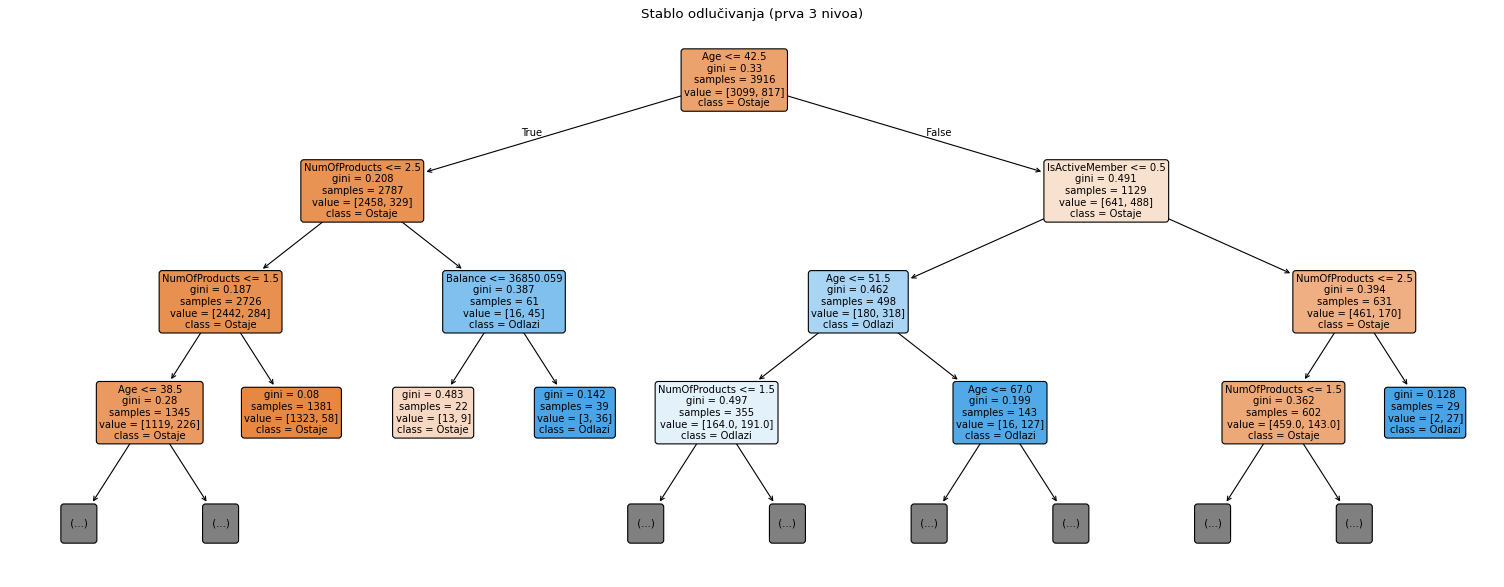

In [12]:
tree = grid.best_estimator_
print('Dubina stabla:', tree.get_depth(), '| broj listova:', tree.get_n_leaves())
plt.figure(figsize=(24, 9))
plot_tree(tree, feature_names=X_train.columns, class_names=['Ostaje', 'Odlazi'],
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title('Stablo odlučivanja (prva 3 nivoa)')
plt.show()

## 8. Evaluacija na test skupu

              precision    recall  f1-score   support

      Ostaje      0.877     0.950     0.912       775
      Odlazi      0.721     0.495     0.587       204

    accuracy                          0.855       979
   macro avg      0.799     0.722     0.750       979
weighted avg      0.845     0.855     0.844       979

ROC-AUC: 0.824


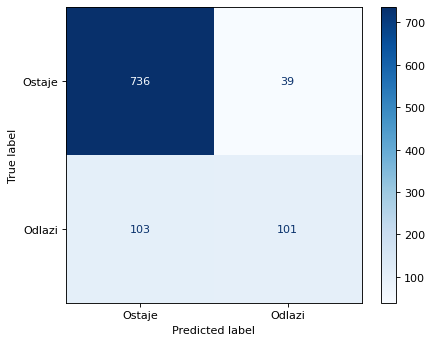

In [13]:
y_pred = tree.predict(X_test)
y_proba = tree.predict_proba(X_test)[:, 1]

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['Ostaje', 'Odlazi']).plot(cmap=plt.cm.Blues)
plt.show()
print(classification_report(y_test, y_pred, target_names=['Ostaje', 'Odlazi'], digits=3))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 3))

## 9. Izbor praga odlučivanja
Podrazumevano, klijenta označavamo kao rizičnog kada je predviđena verovatnoća odlaska 0,5 ili više.
Propušten klijent koji odlazi (izgubljen prihod) obično košta više od lažne uzbune (nepotreban popust), pa **niži prag** može biti bolji poslovni izbor: hvata više klijenata koji odlaze, po cenu više lažnih uzbuna.

In [14]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2]:
    p = (y_proba >= t).astype(int)
    rows.append({'prag': t,
                 'recall_odlazi': recall_score(y_test, p),
                 'precision_odlazi': precision_score(y_test, p),
                 'f1': f1_score(y_test, p),
                 'oznaceno_klijenata': p.sum()})
pd.DataFrame(rows).round(3)

   prag  recall_odlazi  precision_odlazi     f1  oznaceno_klijenata
0   0.5          0.495             0.721  0.587                 140
1   0.4          0.505             0.715  0.592                 144
2   0.3          0.603             0.624  0.613                 197
3   0.2          0.711             0.474  0.569                 306


## 10. Šta najviše utiče na odlazak?

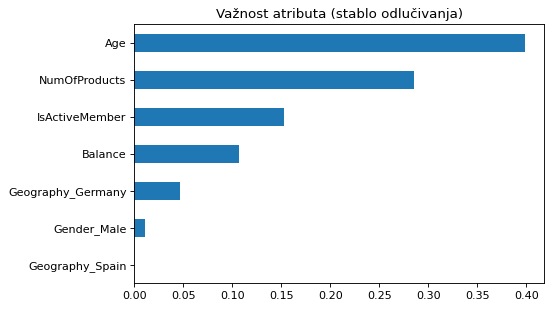

In [15]:
importance = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values()
importance.plot.barh(figsize=(7, 4), title='Važnost atributa (stablo odlučivanja)')
plt.tight_layout()
plt.show()

## Zaključak
- Stablo ima **tačnost 85,5%** i **ROC-AUC 0,82**, dok bazni model ima tačnost 79,2% ali ne pronalazi **nijednog** klijenta koji odlazi.
- Sa podrazumevanim pragom model pronalazi oko polovine klijenata koji odlaze. Spuštanjem praga na **0,3** recall za klijente koji odlaze raste sa **50% na 60%**, a precision ostaje iznad 60%.
- **Godine**, **broj proizvoda** i **aktivnost klijenta** su najjači signali odlaska.
- Prag treba izabrati zajedno sa biznisom, na osnovu toga koliko košta propušten klijent, a koliko ponuda za zadržavanje.

**Sledeći koraci:** poređenje sa logističkom regresijom, Random Forest-om i gradient boosting modelima (XGBoost, LightGBM), praćenje eksperimenata u MLflow-u i objašnjavanje pojedinačnih predikcija pomoću SHAP vrednosti.